Cell 1: imports and settings

In [10]:
import os #to import the local dataset file
import pandas as pd # its for dataframe
import matplotlib.pyplot as plt #its for visulization
import seaborn as sns ##its for visulization


sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"]=(12,4)
COUNTRY="India"
HORIZON=30
Data_dir=os.environ.get("Data_dirs",r"C:\Users\aakas\OneDrive\Desktop\projects list\projects\COVID\covid-19\dataset")

Cell 2: load the three files

In [11]:
confirmed=pd.read_csv(os.path.join(Data_dir,"time_series_covid19_confirmed_global.csv"))
deaths=pd.read_csv(os.path.join(Data_dir,"time_series_covid19_deaths_global.csv"))
recovered=pd.read_csv(os.path.join(Data_dir,"time_series_covid19_recovered_global.csv"))

print(confirmed.shape)
confirmed.iloc[:3,:8]

(266, 248)


,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0
1,NaN,Albania,41.15330,20.168300,0,0,0,0
2,NaN,Algeria,28.03390,1.659600,0,0,0,0


In [12]:
print(confirmed.columns)
print(deaths.columns)
print(recovered.columns)


Index(['Province/State', 'Country/Region', 'Lat', 'Long', '1/22/20', '1/23/20',
       '1/24/20', '1/25/20', '1/26/20', '1/27/20',
       ...
       '9/12/20', '9/13/20', '9/14/20', '9/15/20', '9/16/20', '9/17/20',
       '9/18/20', '9/19/20', '9/20/20', '9/21/20'],
      dtype='str', length=248)
Index(['Province/State', 'Country/Region', 'Lat', 'Long', '1/22/20', '1/23/20',
       '1/24/20', '1/25/20', '1/26/20', '1/27/20',
       ...
       '9/12/20', '9/13/20', '9/14/20', '9/15/20', '9/16/20', '9/17/20',
       '9/18/20', '9/19/20', '9/20/20', '9/21/20'],
      dtype='str', length=248)
Index(['Province/State', 'Country/Region', 'Lat', 'Long', '1/22/20', '1/23/20',
       '1/24/20', '1/25/20', '1/26/20', '1/27/20',
       ...
       '9/12/20', '9/13/20', '9/14/20', '9/15/20', '9/16/20', '9/17/20',
       '9/18/20', '9/19/20', '9/20/20', '9/21/20'],
      dtype='str', length=248)


Cell 3: turn wide into a time series for one country

In [13]:
def country_series(df,country):
    rows=df[df["Country/Region"]==country]
    dates=rows.columns[4:]
    s=rows[dates].sum()
    s.index=pd.to_datetime(s.index,format="%m/%d/%y")
    return s
cum_cases =country_series(confirmed,COUNTRY)
cum_deaths =country_series(deaths,COUNTRY)

print(cum_cases.head())

cum_deaths.head()

2020-01-22    0
2020-01-23    0
2020-01-24    0
2020-01-25    0
2020-01-26    0
dtype: int64


2020-01-22    0
2020-01-23    0
2020-01-24    0
2020-01-25    0
2020-01-26    0
dtype: int64

Cell 4: plot the cumulative curve

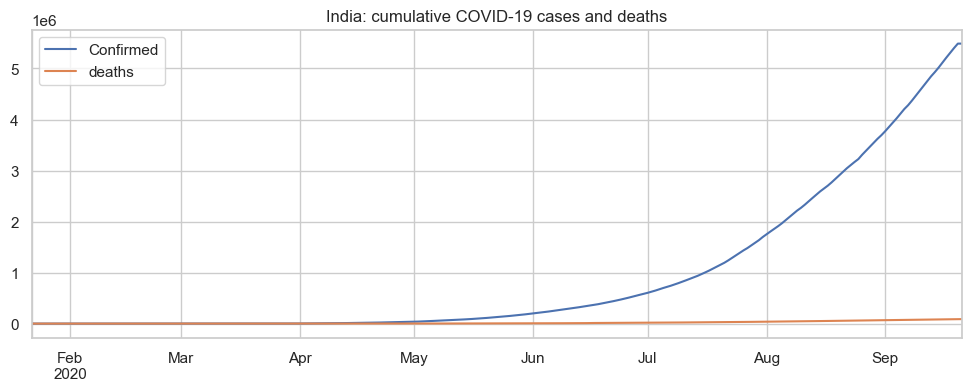

In [14]:
cum_cases.plot(label="Confirmed")
cum_deaths.plot(label="deaths")
plt.title(f"{COUNTRY}: cumulative COVID-19 cases and deaths")
plt.legend()
plt.show()

Step 2: Cumulative to daily new cases, and cleaning

Cell 5: convert to daily

In [15]:
daily = cum_cases.diff().fillna(0)      # today's total minus yesterday's total
daily_deaths = cum_deaths.diff().fillna(0)


daily.describe()

count      244.000000
mean     22490.081967
std      30070.677207
min          0.000000
25%         37.750000
50%       6172.500000
75%      41433.000000
max      97894.000000
dtype: float64

In [16]:
daily.tail()

2020-09-17    96424.0
2020-09-18    93337.0
2020-09-19    92605.0
2020-09-20    86961.0
2020-09-21        0.0
dtype: float64

Cell 6: check for problems

In [17]:
print("Negative days:", (daily < 0).sum())
print("Missing days:", daily.isna().sum())
print("Date gaps:", (daily.index.to_series().diff().dropna() != pd.Timedelta(days=1)).sum())

daily[daily < 0]

Negative days: 0
Missing days: 0
Date gaps: 0


Series([], dtype: float64)

Cell 7: fix negatives

In [19]:
daily_clean = daily.clip(lower=0)

Cell 8: smooth with a 7-day average

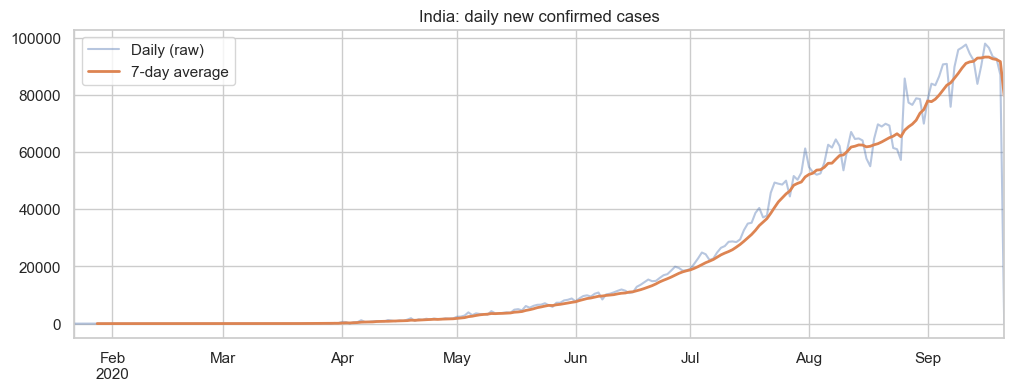

In [20]:
daily_smooth = daily_clean.rolling(window=7, center=False).mean()

daily_clean.plot(alpha=0.4, label="Daily (raw)")
daily_smooth.plot(linewidth=2, label="7-day average")
plt.title(f"{COUNTRY}: daily new confirmed cases")
plt.legend()
plt.show()

Cell 9: inspect the last days

In [21]:
print(daily_clean.tail(8))

# Is it only India? Check whether other big countries also drop on the last day
for c in ["India", "US", "Brazil"]:
    s = country_series(confirmed, c).diff()
    print(c, "last day vs previous-day:", int(s.iloc[-1]), "vs", int(s.iloc[-2]))

2020-09-14    83809.0
2020-09-15    90123.0
2020-09-16    97894.0
2020-09-17    96424.0
2020-09-18    93337.0
2020-09-19    92605.0
2020-09-20    86961.0
2020-09-21        0.0
dtype: float64
India last day vs previous-day: 0 vs 86961
US last day vs previous-day: 52070 vs 36695
Brazil last day vs previous-day: 13411 vs 16389


Cell 10: drop the incomplete last day

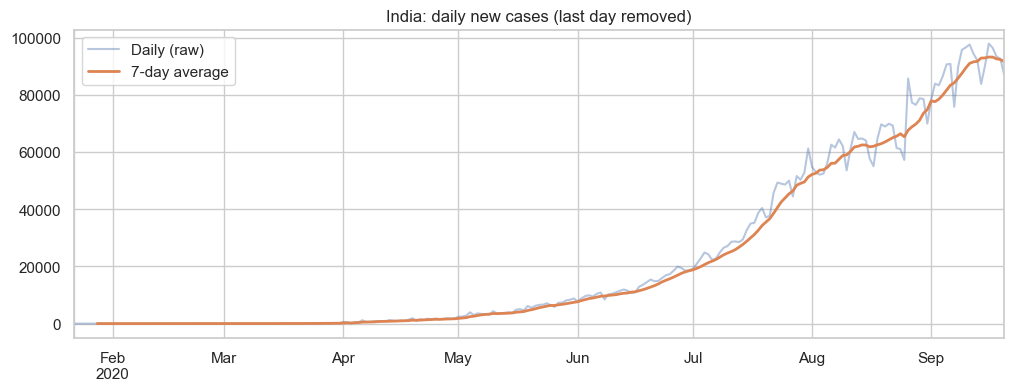

In [22]:
daily_clean = daily_clean.iloc[:-1]
daily_smooth = daily_clean.rolling(7).mean()

daily_clean.plot(alpha=0.4, label="Daily (raw)")
daily_smooth.plot(linewidth=2, label="7-day average")
plt.title(f"{COUNTRY}: daily new cases (last day removed)")
plt.legend(); plt.show()

Cell 11: where does India rank?

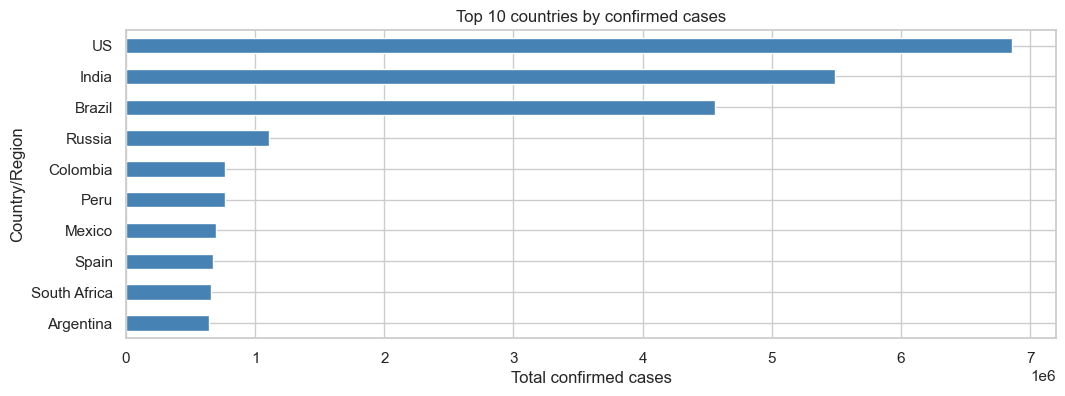

In [23]:
latest = confirmed.groupby("Country/Region")[confirmed.columns[-1]].sum()
top10 = latest.sort_values(ascending=False).head(10)

top10.plot(kind="barh", color="steelblue")
plt.gca().invert_yaxis()
plt.title("Top 10 countries by confirmed cases")
plt.xlabel("Total confirmed cases")
plt.show()

Cell 12: death rate over time

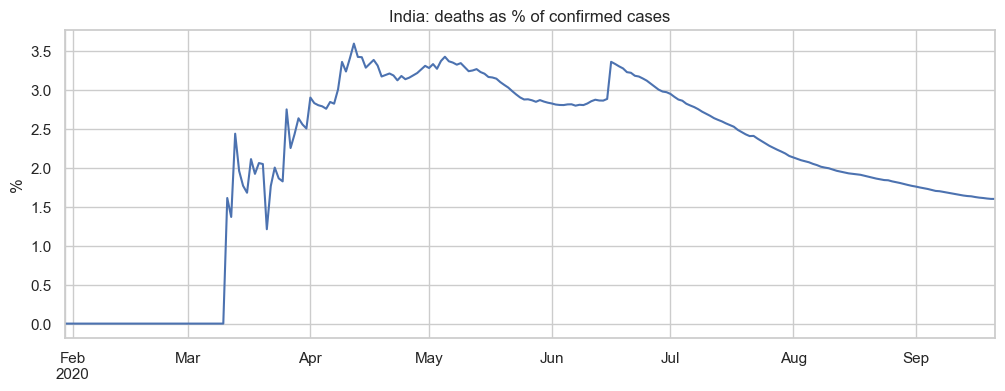

In [24]:
death_rate = (cum_deaths / cum_cases * 100).dropna()
death_rate.plot()
plt.title(f"{COUNTRY}: deaths as % of confirmed cases")
plt.ylabel("%"); plt.show()

Cell 13: growth, is it speeding up or slowing down?

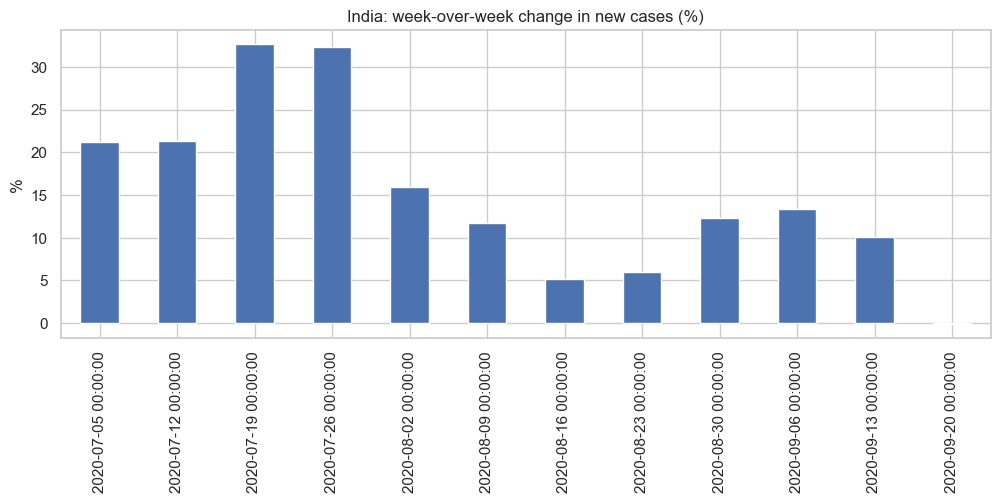

In [25]:
weekly = daily_clean.resample("W").sum()
growth = weekly.pct_change() * 100

growth.tail(12).plot(kind="bar")
plt.title(f"{COUNTRY}: week-over-week change in new cases (%)")
plt.ylabel("%"); plt.show()

Cell 14: split

Train: 2020-01-22 to 2020-08-21 213 days
Test:  2020-08-22 to 2020-09-20 30 days


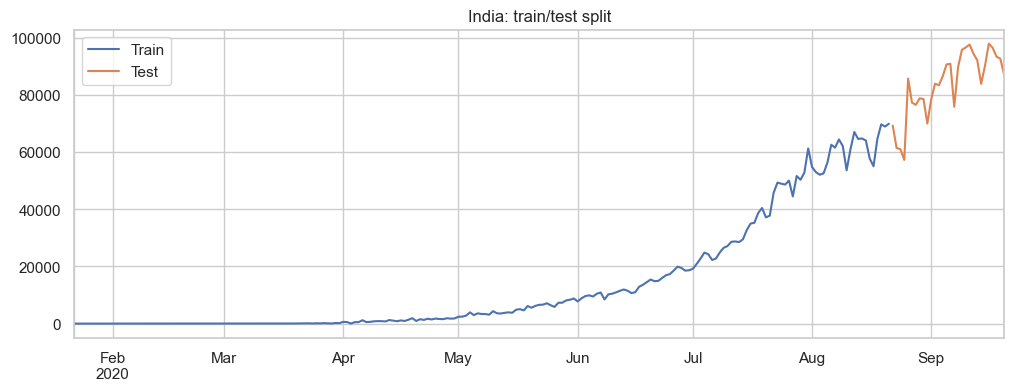

In [26]:
series = daily_clean.copy()

train = series.iloc[:-HORIZON]
test  = series.iloc[-HORIZON:]

print("Train:", train.index[0].date(), "to", train.index[-1].date(), len(train), "days")
print("Test: ", test.index[0].date(),  "to", test.index[-1].date(),  len(test),  "days")

train.plot(label="Train")
test.plot(label="Test")
plt.title(f"{COUNTRY}: train/test split")
plt.legend(); plt.show()

Cell 15: metrics helper

In [27]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

results = []

def evaluate(y_true, y_pred, name):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = (np.abs(y_true - y_pred) / y_true.replace(0, np.nan)).mean() * 100
    results.append({"Model": name, "MAE": round(mae), "RMSE": round(rmse), "MAPE %": round(mape, 1)})
    return results[-1]

Cell 16: two baselines

{'Model': 'Naive (last value)', 'MAE': 15897, 'RMSE': 17820, 'MAPE %': np.float64(18.2)}
{'Model': '7-day average', 'MAE': 20352, 'RMSE': 22470, 'MAPE %': np.float64(23.1)}


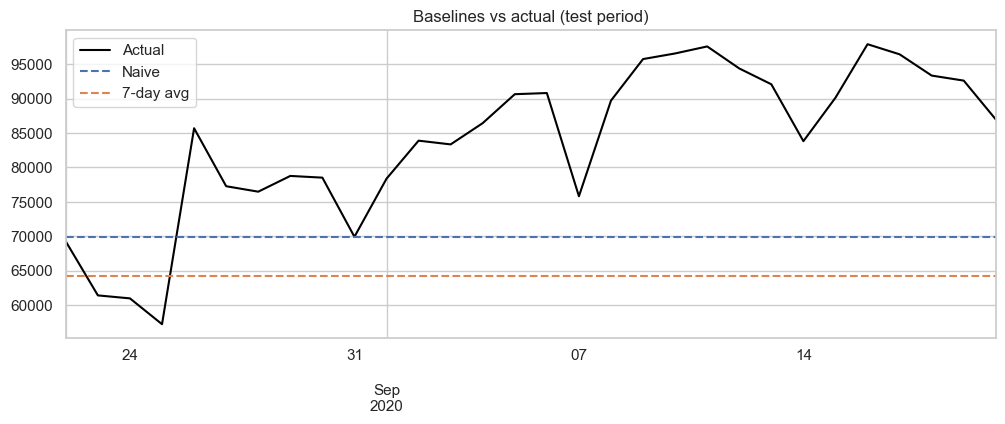

In [28]:
# Baseline 1: "every future day equals the last day we saw"
naive_pred = pd.Series(train.iloc[-1], index=test.index)

# Baseline 2: "every future day equals the average of the last 7 days"
avg7_pred = pd.Series(train.iloc[-7:].mean(), index=test.index)

print(evaluate(test, naive_pred, "Naive (last value)"))
print(evaluate(test, avg7_pred,  "7-day average"))

test.plot(label="Actual", color="black")
naive_pred.plot(label="Naive", linestyle="--")
avg7_pred.plot(label="7-day avg", linestyle="--")
plt.title("Baselines vs actual (test period)")
plt.legend(); plt.show()

Cell 17: build the features

In [29]:
lags = [1, 2, 3, 7, 14]

def make_features(s):
    df = pd.DataFrame({"y": s})
    for l in lags:
        df[f"lag_{l}"] = s.shift(l)      # value l days ago
    df["dow"] = s.index.dayofweek        # 0=Mon ... 6=Sun
    return df.dropna()                   # first 14 days have no lags

train_df = make_features(train)
X_train = train_df.drop(columns="y")
y_train = train_df["y"]

X_train.tail(3)

,lag_1,lag_2,lag_3,lag_7,lag_14,dow
2020-08-19,64572.0,55018.0,57711.0,66999.0,56282.0,2
2020-08-20,69672.0,64572.0,55018.0,64553.0,62538.0,3
2020-08-21,68900.0,69672.0,64572.0,64732.0,61537.0,4


Cell 18: forecast 30 days ahead, one day at a time

In [30]:
def recursive_forecast(model, history, steps):
    hist = list(history.values)
    dates = pd.date_range(history.index[-1] + pd.Timedelta(days=1), periods=steps)
    preds = []
    for d in dates:
        row = {f"lag_{l}": hist[-l] for l in lags}
        row["dow"] = d.dayofweek
        x = pd.DataFrame([row])[X_train.columns]
        p = max(model.predict(x)[0], 0)   # cases can't be negative
        preds.append(p)
        hist.append(p)                    # feed our own prediction back in
    return pd.Series(preds, index=dates)

Cell 19: train and evaluate two models

{'Model': 'Linear Regression (lags)', 'MAE': 6600, 'RMSE': 8851, 'MAPE %': np.float64(8.2)}
{'Model': 'Random Forest (lags)', 'MAE': 18109, 'RMSE': 20121, 'MAPE %': np.float64(20.6)}


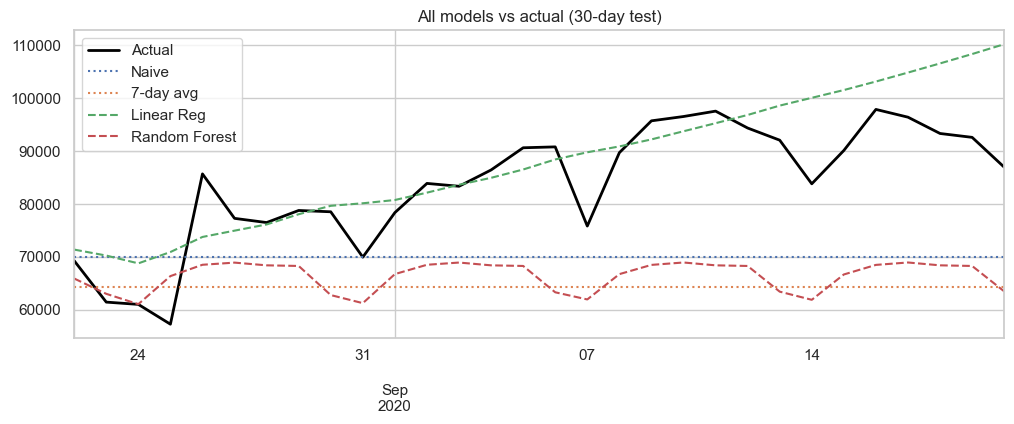

,Model,MAE,RMSE,MAPE %
0,Naive (last value),15897,17820,18.2
1,7-day average,20352,22470,23.1
2,Linear Regression (lags),6600,8851,8.2
3,Random Forest (lags),18109,20121,20.6


In [31]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

lr = LinearRegression().fit(X_train, y_train)
rf = RandomForestRegressor(n_estimators=200, random_state=42).fit(X_train, y_train)

lr_pred = recursive_forecast(lr, train, HORIZON)
rf_pred = recursive_forecast(rf, train, HORIZON)

print(evaluate(test, lr_pred, "Linear Regression (lags)"))
print(evaluate(test, rf_pred, "Random Forest (lags)"))

test.plot(label="Actual", color="black", linewidth=2)
naive_pred.plot(label="Naive", linestyle=":")
avg7_pred.plot(label="7-day avg", linestyle=":")
lr_pred.plot(label="Linear Reg", linestyle="--")
rf_pred.plot(label="Random Forest", linestyle="--")
plt.title("All models vs actual (30-day test)")
plt.legend(); plt.show()

pd.DataFrame(results)

Cell 20: does the data need differencing?

In [32]:
from statsmodels.tsa.stattools import adfuller

def adf_pvalue(s):
    return adfuller(s.dropna())[1]

print("Original series p-value:   ", round(adf_pvalue(train), 4))
print("After 1 difference p-value:", round(adf_pvalue(train.diff()), 4))
print("After 2 differences p-value:", round(adf_pvalue(train.diff().diff()), 4))

Original series p-value:    0.993
After 1 difference p-value: 0.5922
After 2 differences p-value: 0.0


C:\Users\aakas\AppData\Local\Temp\ipykernel_13552\4005058597.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return adfuller(s.dropna())[1]
C:\Users\aakas\AppData\Local\Temp\ipykernel_13552\4005058597.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return adfuller(s.dropna())[1]
C:\Users\aakas\AppData\Local\Temp\ipykernel_13552\4005058597.py:4: FutureWarning: adfu

Cell 21: try a small grid of (p, d, q) and pick the best by AIC

In [33]:


import warnings
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")

d = 1  # change this to what Cell 20 told you
best = None

for p in range(0, 4):
    for q in range(0, 4):
        try:
            fit = ARIMA(train, order=(p, d, q)).fit()
            if best is None or fit.aic < best[0]:
                best = (fit.aic, (p, d, q), fit)
        except Exception:
            continue

print("Best order:", best[1], "| AIC:", round(best[0]))
arima_fit = best[2]

Best order: (3, 1, 3) | AIC: 3756


Cell 22: forecast and evaluate

{'Model': 'ARIMA(3, 1, 3)', 'MAE': 12893, 'RMSE': 14455, 'MAPE %': np.float64(14.8)}


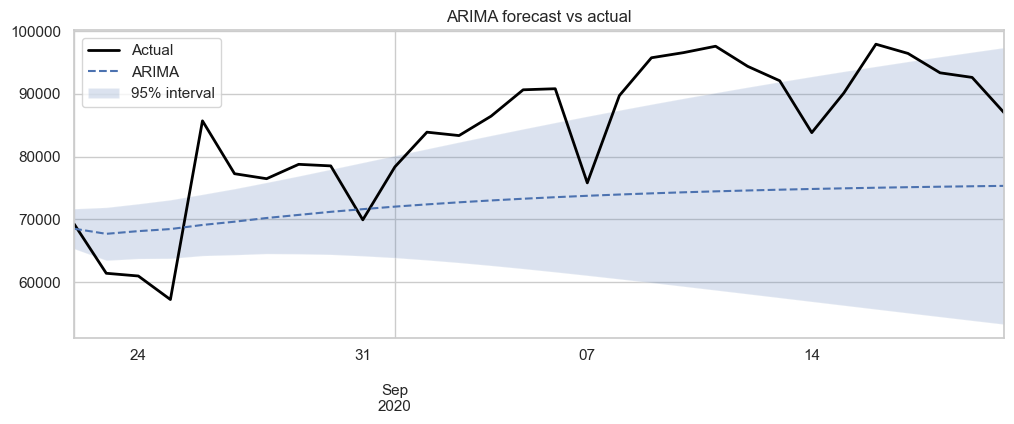

,Model,MAE,RMSE,MAPE %
0,Naive (last value),15897,17820,18.2
1,7-day average,20352,22470,23.1
2,Linear Regression (lags),6600,8851,8.2
3,Random Forest (lags),18109,20121,20.6
4,"ARIMA(3, 1, 3)",12893,14455,14.8


In [34]:
fc = arima_fit.get_forecast(steps=HORIZON)
arima_pred = fc.predicted_mean.clip(lower=0)
arima_pred.index = test.index
conf = fc.conf_int()
conf.index = test.index

print(evaluate(test, arima_pred, f"ARIMA{best[1]}"))

test.plot(label="Actual", color="black", linewidth=2)
arima_pred.plot(label="ARIMA", linestyle="--")
plt.fill_between(test.index, conf.iloc[:, 0].clip(lower=0), conf.iloc[:, 1], alpha=0.2, label="95% interval")
plt.title("ARIMA forecast vs actual")
plt.legend(); plt.show()

pd.DataFrame(results)

Cell 23: clean results table

In [35]:
res = (pd.DataFrame(results)
         .drop_duplicates("Model", keep="last")   # re-running cells adds duplicate rows
         .sort_values("MAE")
         .reset_index(drop=True))
res

,Model,MAE,RMSE,MAPE %
0,Linear Regression (lags),6600,8851,8.2
1,"ARIMA(3, 1, 3)",12893,14455,14.8
2,Naive (last value),15897,17820,18.2
3,Random Forest (lags),18109,20121,20.6
4,7-day average,20352,22470,23.1


Cell 24: visual comparison

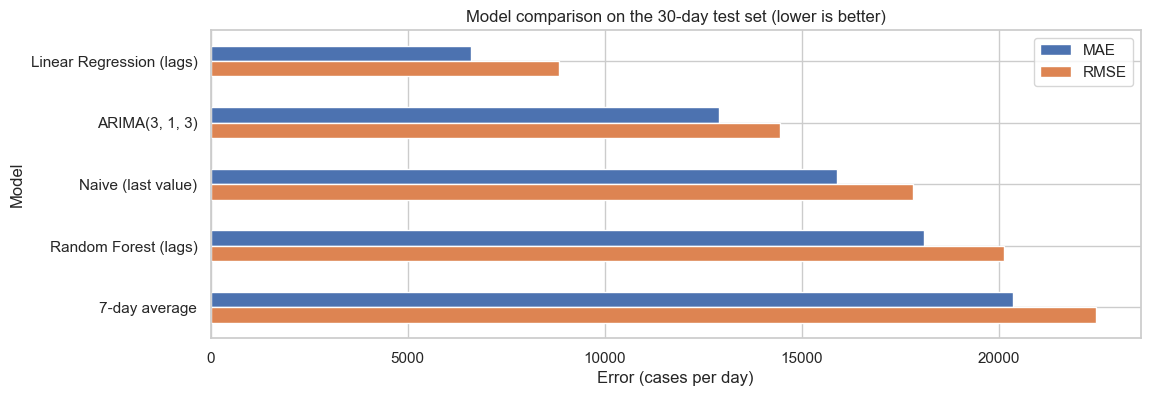

In [36]:
res.set_index("Model")[["MAE", "RMSE"]].plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Model comparison on the 30-day test set (lower is better)")
plt.xlabel("Error (cases per day)")
plt.show()

Cell 25: how does error grow over the forecast horizon?

In [37]:
all_preds = {
    "Naive": naive_pred,
    "7-day avg": avg7_pred,
    "Linear Reg": lr_pred,
    "Random Forest": rf_pred,
    "ARIMA": arima_pred,
}

rows = []
for name, p in all_preds.items():
    err = (test - p).abs()
    rows.append({
        "Model": name,
        "Week 1": err.iloc[:7].mean(),
        "Week 2": err.iloc[7:14].mean(),
        "Week 3": err.iloc[14:21].mean(),
        "Week 4+": err.iloc[21:].mean(),
    })

pd.DataFrame(rows).set_index("Model").round(0)

,Week 1,Week 2,Week 3,Week 4+
Model,,,,
Naive,8636.0,10011.0,21096.0,22079.0
7-day avg,9258.0,15633.0,26718.0,27701.0
Linear Reg,6713.0,2565.0,4320.0,11422.0
Random Forest,6824.0,13506.0,24419.0,25559.0
ARIMA,7982.0,8423.0,17057.0,16951.0


Cell 26: pick the winner, with a sanity rule

In [38]:
best_row = res.iloc[0]
baseline_mae = res.loc[res["Model"] == "7-day average", "MAE"].iloc[0]
improvement = (1 - best_row["MAE"] / baseline_mae) * 100

print(f"Best model: {best_row['Model']}")
print(f"MAE: {best_row['MAE']:,.0f} cases/day | MAPE: {best_row['MAPE %']}%")
print(f"Improvement over 7-day average baseline: {improvement:.1f}%")

Best model: Linear Regression (lags)
MAE: 6,600 cases/day | MAPE: 8.2%
Improvement over 7-day average baseline: 67.6%


Cell 27: refit the best model on the full series and forecast

In [39]:
best_name = res.iloc[0]["Model"]
print("Using:", best_name)

if best_name.startswith("ARIMA"):
    final_fit = ARIMA(series, order=best[1]).fit()
    fc = final_fit.get_forecast(steps=HORIZON)
    future = fc.predicted_mean.clip(lower=0)
    ci = fc.conf_int().clip(lower=0)
else:
    full_df = make_features(series)
    X_full, y_full = full_df.drop(columns="y"), full_df["y"]
    model = (LinearRegression() if "Linear" in best_name
             else RandomForestRegressor(n_estimators=200, random_state=42))
    model.fit(X_full, y_full)
    future = recursive_forecast(model, series, HORIZON)
    ci = None   # only ARIMA gives an interval; see the note below

print(future.round(0).describe())

Using: Linear Regression (lags)
count        30.000000
mean     109076.066667
std       10102.706759
min       90232.000000
25%       99775.250000
50%      107937.500000
75%      117147.250000
max      126548.000000
dtype: float64


Cell 28: plot history plus forecast

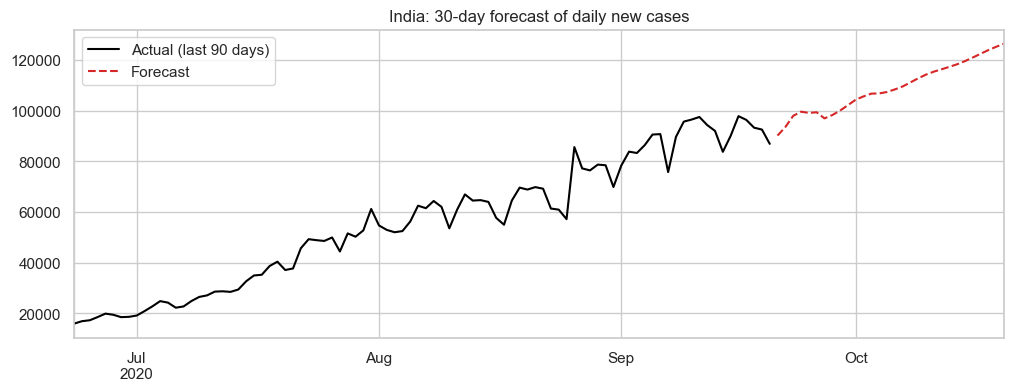

In [40]:
series.iloc[-90:].plot(label="Actual (last 90 days)", color="black")
future.plot(label="Forecast", linestyle="--", color="tab:red")
if ci is not None:
    plt.fill_between(future.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=0.2, color="tab:red", label="95% interval")
plt.title(f"{COUNTRY}: {HORIZON}-day forecast of daily new cases")
plt.legend(); plt.show()

Cell 29: turn the forecast into planning numbers

In [41]:
last_week_avg = series.iloc[-7:].mean()
fc_avg  = future.mean()
fc_peak = future.max()
fc_total = future.sum()
change = (fc_avg / last_week_avg - 1) * 100

print(f"Last 7-day average:       {last_week_avg:,.0f} cases/day")
print(f"Forecast average:         {fc_avg:,.0f} cases/day ({change:+.1f}% vs last week)")
print(f"Forecast peak day:        {fc_peak:,.0f} on {future.idxmax().date()}")
print(f"Expected new cases total: {fc_total:,.0f} over {HORIZON} days")

# Illustrative planning assumptions: replace with figures from an official source
HOSPITAL_RATE = 0.05   # share of cases needing hospital care (ASSUMPTION)
AVG_STAY_DAYS = 10     # average length of stay (ASSUMPTION)

beds_needed = fc_avg * HOSPITAL_RATE * AVG_STAY_DAYS
print(f"Rough hospital beds needed at any time: {beds_needed:,.0f}")

Last 7-day average:       91,593 cases/day
Forecast average:         109,076 cases/day (+19.1% vs last week)
Forecast peak day:        126,548 on 2020-10-20
Expected new cases total: 3,272,285 over 30 days
Rough hospital beds needed at any time: 54,538


Cell 30: refit all models on the full series and compare their forecasts

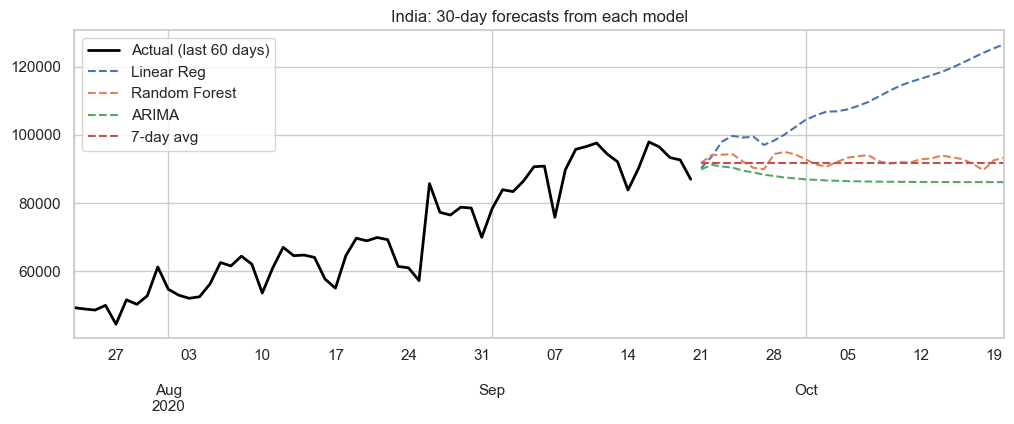

,Avg/day,Peak,Total
Linear Reg,109076.0,126548.0,3272285.0
Random Forest,92613.0,94969.0,2778398.0
ARIMA,87239.0,91184.0,2617175.0
7-day avg,91593.0,91593.0,2747799.0


In [44]:
full_df = make_features(series)
X_full, y_full = full_df.drop(columns="y"), full_df["y"]

final_preds = {}
final_preds["Linear Reg"] = recursive_forecast(
    LinearRegression().fit(X_full, y_full), series, HORIZON)
final_preds["Random Forest"] = recursive_forecast(
    RandomForestRegressor(n_estimators=200, random_state=42).fit(X_full, y_full), series, HORIZON)

fut_index = final_preds["Linear Reg"].index
arima_full = ARIMA(series, order=best[1]).fit()
final_preds["ARIMA"] = pd.Series(
    arima_full.get_forecast(HORIZON).predicted_mean.clip(lower=0).values, index=fut_index)
final_preds["7-day avg"] = pd.Series(series.iloc[-7:].mean(), index=fut_index)

series.iloc[-60:].plot(color="black", label="Actual (last 60 days)", linewidth=2)
for name, p in final_preds.items():
    p.plot(linestyle="--", label=name)
plt.title(f"{COUNTRY}: 30-day forecasts from each model")
plt.legend(); plt.show()

pd.DataFrame({n: {"Avg/day": p.mean(), "Peak": p.max(), "Total": p.sum()}
              for n, p in final_preds.items()}).T.round(0)

Cell 31: backtest over 4 windows

In [46]:
def backtest(series, n_folds=4):
    rows = []
    for i in range(n_folds):
        end = len(series) - i * HORIZON
        tr, te = series.iloc[:end - HORIZON], series.iloc[end - HORIZON:end]

        fdf = make_features(tr)
        X, y = fdf.drop(columns="y"), fdf["y"]

        preds = {
            "7-day avg": pd.Series(tr.iloc[-7:].mean(), index=te.index),
            "Linear Reg": recursive_forecast(LinearRegression().fit(X, y), tr, HORIZON),
            "Random Forest": recursive_forecast(
                RandomForestRegressor(n_estimators=100, random_state=42).fit(X, y), tr, HORIZON),
            "ARIMA": pd.Series(
                ARIMA(tr, order=best[1]).fit().get_forecast(HORIZON).predicted_mean.clip(lower=0).values,
                index=te.index),
        }
        for name, p in preds.items():
            p.index = te.index
            rows.append({"Fold": i + 1, "Model": name, "MAE": mean_absolute_error(te, p)})
    return pd.DataFrame(rows)

bt = backtest(series)
(bt.pivot(index="Model", columns="Fold", values="MAE")
   .assign(Mean=lambda d: d.mean(axis=1))
   .round(0).sort_values("Mean"))

Fold,1,2,3,4,Mean
Model,,,,,
ARIMA,12893.0,4988.0,8185.0,1468.0,6883.0
Linear Reg,6600.0,18891.0,2324.0,4567.0,8095.0
Random Forest,17973.0,14635.0,11714.0,3895.0,12054.0
7-day avg,20352.0,19334.0,12745.0,4468.0,14225.0


Cell 32: headline forecast with interval

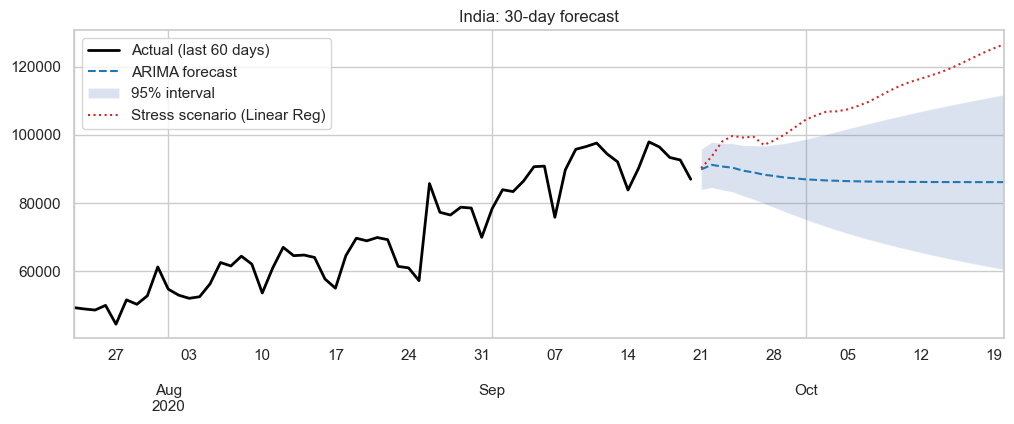

Central forecast: 87,239 cases/day, total 2,617,175
95% interval for the 30-day average: 71,700 to 102,779
Stress scenario:  109,076 cases/day, total 3,272,285


In [47]:
arima_final = ARIMA(series, order=best[1]).fit()
fc = arima_final.get_forecast(HORIZON)
mean_fc = fc.predicted_mean.clip(lower=0)
ci = fc.conf_int().clip(lower=0)

series.iloc[-60:].plot(color="black", label="Actual (last 60 days)", linewidth=2)
mean_fc.plot(color="tab:blue", linestyle="--", label="ARIMA forecast")
plt.fill_between(mean_fc.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=0.2, label="95% interval")
final_preds["Linear Reg"].plot(color="tab:red", linestyle=":", label="Stress scenario (Linear Reg)")
plt.title(f"{COUNTRY}: 30-day forecast")
plt.legend(); plt.show()

print(f"Central forecast: {mean_fc.mean():,.0f} cases/day, total {mean_fc.sum():,.0f}")
print(f"95% interval for the 30-day average: {ci.iloc[:, 0].mean():,.0f} to {ci.iloc[:, 1].mean():,.0f}")
print(f"Stress scenario:  {final_preds['Linear Reg'].mean():,.0f} cases/day, total {final_preds['Linear Reg'].sum():,.0f}")

## Forecast and recommendations for the health department (India, 30 days)

**Forecast (ARIMA, retrained on all data):** about 87,000 new cases/day on average
(2.6 million over 30 days), roughly 5% below the last 7-day average of 91,600.
The 95% interval for the 30-day average is about 72,000 to 103,000 cases/day.
A stress scenario from Linear Regression (109,000/day, 3.3 million total) lies above
this interval and is treated as a worst case, not an expected outcome.

**Recommendations**
1. **Plan for the upper bound, not the central number.** Size hospital capacity to about
   103,000 cases/day (illustrative: about 51,000 beds at a 5% hospitalisation rate and
   10-day stay; replace with official figures).
2. **Hold capacity steady; do not scale down yet.** Cases are on a high plateau, so
   keep testing, oxygen, ICU and staffing at current levels until the 7-day average
   falls consistently for several weeks.
3. **Stage any easing of restrictions** and watch the 7-day average for a rebound.
4. **Use quieter weeks to restock** (oxygen, medicines, protective equipment) and
   prepare surge facilities that can be activated quickly.
5. **Review weekly.** Re-run the forecast every week with new data; a 30-day forecast
   loses reliability as the epidemic changes.
6. **Improve data quality**: weekend reporting dips and incomplete final days distort
   short-term numbers, so decisions should use 7-day averages.

**Limitations:** the data ends in September 2020, so this is advice as of that date;
forecasts use past case counts only and cannot anticipate lockdowns, variants, or
changes in testing; backtesting used four windows, which is limited evidence.